# 04 · Learning to rank root causes with XGBoost (GPU)

**Learning to rank:** instead of predicting a class for each row independently, the model learns to *order* the services of a case so the culprit comes first. XGBoost's `rank:pairwise` objective looks at pairs (culprit, innocent service) inside the same case and learns to score the culprit higher.

### Honest evaluation (the most important part of this notebook)
We only have 270 cases, so we use **cross-validation** (train on part, test on the rest, rotate):
1. **Grouped 5-fold CV:** the 3 repetitions of the same (system, service, fault) always land in the same fold, so the model is tested on failures it has never seen a copy of. Repeated with 3 different shuffles (seeds) to average out luck.
2. **Leave-one-system-out:** train on two systems, test on the third. This is the toughest test: does the model generalise to a system it has *never seen*? (Closest to deploying it on a new bank application.)

Every case gets exactly one *out-of-fold* prediction per repetition of the CV, so all 270 cases are scored by a model that did not see them.

We compare with the best rule from notebook 03 and report **bootstrap confidence intervals** for the difference.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", message=".*(mismatched devices|pandas version 4).*")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
RESULTS = ROOT / "reports" / "results"; RESULTS.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

from rcalens.data import load_features, case_index
from rcalens.evaluate import evaluate, true_ranks, rank_metrics, bootstrap_diff, grouped_folds, leave_one_system_out
from rcalens.models import gpu_device, feature_columns, fit_ranker, fault_frame, fit_fault_classifier, FAULTS
df, has_traces = load_features()
cases = df.drop_duplicates("case")[["case", "system", "pair", "fault"]].reset_index(drop=True)
DEVICE = gpu_device()
print("training device:", DEVICE, "| trace features:", has_traces, "| cases:", len(cases))
base = json.load(open(RESULTS / "baselines.json"))
base_scores = pd.read_parquet(ROOT / "data" / "processed" / "baseline_scores.parquet")
print("best rule from notebook 03:", base["best_rule"], base["overall"][base["best_rule"]])

training device: cuda | trace features: True | cases: 270
best rule from notebook 03: rank average (all features) {'AC@1': 0.7074, 'AC@3': 0.9259, 'AC@5': 0.963, 'Avg@5': 0.8822, 'MRR': 0.8201}


In [2]:
def cv_scores(cols, seeds=(0, 1, 2), **params):
    """Grouped 5-fold CV, repeated over seeds. Returns one out-of-fold score per (case, service) per seed."""
    outs = []
    for seed in seeds:
        for tr_c, te_c in grouped_folds(cases, n_splits=5, seed=seed):
            m = fit_ranker(df[df["case"].isin(tr_c)], cols, DEVICE, seed=seed, **params)
            te = df[df["case"].isin(te_c)][["case", "system", "service", "is_rc"]].copy()
            te["score"] = m.predict(df.loc[te.index, cols]); te["seed"] = seed
            outs.append(te)
    return pd.concat(outs)

def summarise(oof):
    """mean and spread of the metrics across the CV repetitions"""
    per_seed = pd.DataFrame({s: evaluate(g, by_system=False).loc["all"] for s, g in oof.groupby("seed")}).T
    return per_seed.mean(), per_seed.std()

ALL = feature_columns(df)
oof = cv_scores(ALL)
mean, sd = summarise(oof)
pd.DataFrame({"mean": mean, "± sd over CV repeats": sd}).round(3).T

,AC@1,AC@3,AC@5,Avg@5,MRR
mean,0.944,0.990,0.999,0.982,0.968
± sd over CV repeats,0.010,0.008,0.002,0.007,0.007


In [3]:
seed0 = oof[oof["seed"] == 0]
comp = pd.concat({"best rule": evaluate(base_scores), "XGBoost ranker (seed 0)": evaluate(seed0)}, axis=0)
comp.round(3)

AC@1   AC@3   AC@5  Avg@5    MRR
best rule               all  0.707  0.926  0.963  0.882  0.820
                        ob   0.689  0.967  1.000  0.911  0.825
                        ss   0.800  0.956  0.989  0.929  0.882
                        tt   0.633  0.856  0.900  0.807  0.754
XGBoost ranker (seed 0) all  0.941  0.996  1.000  0.985  0.969
                        ob   0.889  1.000  1.000  0.978  0.944
                        ss   0.967  0.989  1.000  0.984  0.978
                        tt   0.967  1.000  1.000  0.993  0.983

### Is the improvement real? Bootstrap over cases
We resample the 270 cases 2,000 times and look at the 95% interval of *(model − rule)*. If it stays above 0, the gain is not luck.

In [4]:
r_model, r_rule = true_ranks(seed0), true_ranks(base_scores)
boot = {m: bootstrap_diff(r_model, r_rule, m) for m in ["AC@1", "AC@3", "Avg@5", "MRR"]}
pd.DataFrame(boot, index=["2.5%", "median", "97.5%"]).T

,2.5%,median,97.5%
AC@1,0.178,0.233,0.289
AC@3,0.041,0.070,0.104
Avg@5,0.078,0.102,0.131
MRR,0.114,0.148,0.184


## Which sources help? (ablation)
Same CV, same seeds, different feature sets.

In [5]:
sets = {"metrics only": feature_columns(df, ("m_",)), "metrics + logs": feature_columns(df, ("m_", "l_"))}
if has_traces:
    sets["metrics + logs + traces (all)"] = ALL
sets["all, without within-case ranks"] = feature_columns(df, ranks=False)
abl = {}
for name, cols in sets.items():
    o = oof if cols == ALL else cv_scores(cols)
    abl[name] = summarise(o)[0]
pd.DataFrame(abl).T.round(3)

,AC@1,AC@3,AC@5,Avg@5,MRR
metrics only,0.951,0.990,0.998,0.983,0.971
metrics + logs,0.942,0.988,0.998,0.981,0.967
metrics + logs + traces (all),0.944,0.990,0.999,0.982,0.968
"all, without within-case ranks",0.957,0.988,0.999,0.983,0.974


## The hard test: leave one system out
Train on two systems, test on the third, never seen during training.

In [6]:
loso = []
for sys_name, tr_c, te_c in leave_one_system_out(cases):
    m = fit_ranker(df[df["case"].isin(tr_c)], ALL, DEVICE, seed=0)
    te = df[df["case"].isin(te_c)][["case", "system", "service", "is_rc"]].copy(); te["score"] = m.predict(df.loc[te.index, ALL])
    loso.append(te)
loso = pd.concat(loso)
pd.concat({"rule (no training)": evaluate(base_scores), "XGBoost, unseen system": evaluate(loso)}, axis=0).round(3)

AC@1   AC@3   AC@5  Avg@5    MRR
rule (no training)     all  0.707  0.926  0.963  0.882  0.820
                       ob   0.689  0.967  1.000  0.911  0.825
                       ss   0.800  0.956  0.989  0.929  0.882
                       tt   0.633  0.856  0.900  0.807  0.754
XGBoost, unseen system all  0.744  0.959  0.981  0.909  0.845
                       ob   0.411  0.978  1.000  0.824  0.659
                       ss   0.956  0.978  1.000  0.982  0.972
                       tt   0.867  0.922  0.944  0.920  0.904

**How to read it:** if the "unseen system" numbers stay close to the grouped-CV numbers, the model learned general failure behaviour. If they drop a lot, it partly memorised system-specific patterns, which is useful to know before deploying it anywhere new.

## Shortcut check: can it find a culprit it has never seen as a culprit?
Each system has only 5 services that the benchmark ever breaks. A model could cheat by learning to recognise *those 5 services* (e.g. by which metrics they expose) instead of learning failure behaviour. To rule this out we hold out **all cases of one root-cause service** (all its faults and repetitions), train on the rest, and test on the held-out ones, 15 times. In training, that service only ever appears as an *innocent* service.

In [7]:
lorso = []
for (s, svc), g in df.drop_duplicates("case").groupby(["system", "root_cause_service"]):
    m = fit_ranker(df[~df["case"].isin(g["case"])], ALL, DEVICE, seed=0)
    te = df[df["case"].isin(g["case"])][["case", "system", "service", "is_rc"]].copy(); te["score"] = m.predict(df.loc[te.index, ALL])
    lorso.append(te)
lorso = pd.concat(lorso)
evaluate(lorso).round(3)

,AC@1,AC@3,AC@5,Avg@5,MRR
all,0.944,0.993,1.0,0.986,0.970
ob,0.889,1.000,1.0,0.978,0.944
ss,0.967,0.978,1.0,0.984,0.978
tt,0.978,1.000,1.0,0.996,0.989


If these numbers stay close to the grouped-CV ones, the model learned *how a culprit behaves*, not *which services are usually culprits*.

## Per fault type: where does the model help?

In [8]:
fault = cases.set_index("case")["fault"]
tab = pd.DataFrame({"rule": (r_rule <= 1).groupby(fault.reindex(r_rule.index).to_numpy()).mean(),
                    "XGBoost": (r_model <= 1).groupby(fault.reindex(r_model.index).to_numpy()).mean()})
tab.round(3).T

,cpu,delay,disk,loss,mem,socket
rule,0.889,0.356,0.756,0.489,0.889,0.867
XGBoost,1.000,0.822,0.978,0.844,1.000,1.000


## Step 2: what kind of fault is it? (fault-type classifier)
Once we have a suspected service, its pattern of anomalies (CPU vs memory vs latency …) tells us the fault type. We train a 6-class XGBoost classifier on the **features of the service ranked first** (using the out-of-fold ranking, so nothing is leaked), with the same grouped folds. We also report an *oracle* version that is given the true culprit, to separate "wrong service" errors from "wrong fault" errors.

In [9]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
def fault_cv(frame):
    pred = pd.Series(index=frame["case"], dtype=object)
    for tr_c, te_c in grouped_folds(cases, n_splits=5, seed=0):
        tr, te = frame[frame["case"].isin(tr_c)], frame[frame["case"].isin(te_c)]
        m, cols = fit_fault_classifier(tr, DEVICE)
        pred[te["case"].to_numpy()] = [FAULTS[i] for i in m.predict(te[cols])]
    truth = frame.set_index("case")["fault"].reindex(pred.index)
    return pred, truth

oracle = df.copy(); oracle["score"] = oracle["is_rc"]
ranked = df.merge(seed0[["case", "service", "score"]], on=["case", "service"])
fault_res = {}
for name, frame in {"service from the ranker (end-to-end)": fault_frame(ranked), "true service (oracle)": fault_frame(oracle)}.items():
    p, t = fault_cv(frame)
    fault_res[name] = {"accuracy": accuracy_score(t, p), "macro_F1": f1_score(t, p, average="macro")}
    if "end-to-end" in name: p_e2e, t_e2e = p, t
pd.DataFrame(fault_res).T.round(3)

,accuracy,macro_F1
service from the ranker (end-to-end),0.826,0.825
true service (oracle),0.848,0.847


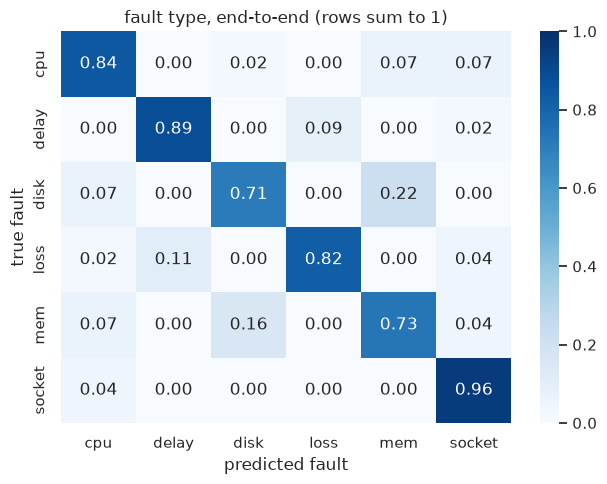

In [10]:
cm = confusion_matrix(t_e2e, p_e2e, labels=FAULTS, normalize="true")
plt.figure(figsize=(6.5, 5)); sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=FAULTS, yticklabels=FAULTS, vmin=0, vmax=1)
plt.xlabel("predicted fault"); plt.ylabel("true fault"); plt.title("fault type, end-to-end (rows sum to 1)"); plt.tight_layout()
plt.savefig(FIG / "fault_confusion.png", dpi=120); plt.show()

## What does the ranker look at?

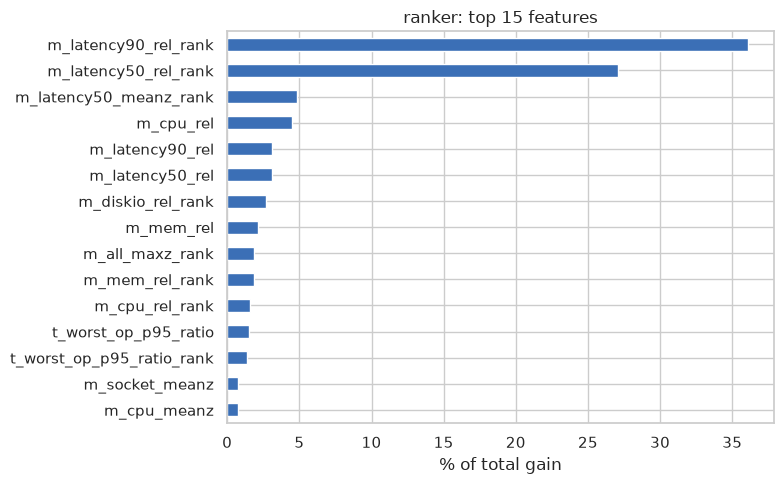

In [11]:
final = fit_ranker(df, ALL, DEVICE, seed=0)
imp = pd.Series(final.get_booster().get_score(importance_type="total_gain")).reindex(ALL).fillna(0)
(imp / imp.sum() * 100).sort_values().tail(15).plot(kind="barh", figsize=(8, 5), color="#3b6fb6")
plt.xlabel("% of total gain"); plt.title("ranker: top 15 features"); plt.tight_layout(); plt.savefig(FIG / "ranker_importance.png", dpi=120); plt.show()
final.save_model(str(ROOT / "models" / "ranker.json"))

In [12]:
results = {"has_traces": has_traces, "device": DEVICE,
           "rule": {k: round(v, 4) for k, v in rank_metrics(r_rule).items()},
           "xgb_grouped_cv_mean": mean.round(4).to_dict(), "xgb_grouped_cv_sd": sd.round(4).to_dict(),
           "xgb_by_system_seed0": evaluate(seed0).round(4).to_dict(orient="index"),
           "xgb_leave_one_system_out": evaluate(loso).round(4).to_dict(orient="index"),
           "xgb_leave_one_rc_service_out": evaluate(lorso).round(4).to_dict(orient="index"),
           "bootstrap_xgb_minus_rule": {k: list(map(float, v)) for k, v in boot.items()},
           "ablation": pd.DataFrame(abl).T.round(4).to_dict(orient="index"),
           "fault_type": {k: {m: round(v, 4) for m, v in d.items()} for k, d in fault_res.items()}}
json.dump(results, open(RESULTS / "ml_ranker.json", "w"), indent=1)
seed0.to_parquet(ROOT / "data" / "processed" / "oof_xgb.parquet", index=False)
print(json.dumps(results["xgb_grouped_cv_mean"], indent=1))

{
 "AC@1": 0.9444,
 "AC@3": 0.9901,
 "AC@5": 0.9988,
 "Avg@5": 0.9817,
 "MRR": 0.9681
}


### Takeaways
*(Filled in after the full run on the training server: see notebook 06 for the final numbers and their interpretation.)*

➡️ Next: **05_deep_learning**: can a neural network reading the raw time series do better?